In [1]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/AugustLONG/ML01/master/01decisiontree/AllElectronics.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   RID                  14 non-null     int64 
 1   age                  14 non-null     object
 2   income               14 non-null     object
 3   student              14 non-null     object
 4   credit_rating        14 non-null     object
 5   class_buys_computer  14 non-null     object
dtypes: int64(1), object(5)
memory usage: 800.0+ bytes


In [2]:
#1. 필요없는 열 제거
df.drop(columns='RID', inplace=True)

# 2. 수동매핑
df['age'] = df['age'].map({'youth': 0, 'middle_aged': 1, 'senior': 2})
df['income'] = df['income'].map({'high': 0, 'medium': 1, 'low': 2})
df['student'] = df['student'].map({'no': 0, 'yes': 1})
df['credit_rating'] = df['credit_rating'].map({'fair': 0, 'excellent': 1})
df['class_buys_computer'] = df['class_buys_computer'].map({"yes": 1, "no": 0})

df

,age,income,student,credit_rating,class_buys_computer
0,0,0,0,0,0
1,0,0,0,1,0
2,1,0,0,0,1
3,2,1,0,0,1
4,2,2,1,0,1
5,2,2,1,1,0
6,1,2,1,1,1
7,0,1,0,0,0
8,0,2,1,0,1
9,2,1,1,0,1


In [3]:
#데이터 분리
y = df.pop("class_buys_computer")
X = df

print(X.shape)
print(y.shape)

(14, 4)
(14,)


In [4]:
# 모델 학습
id3 = DecisionTreeClassifier(criterion='entropy')
id3.fit(X, y)

DecisionTreeClassifier(criterion='entropy')

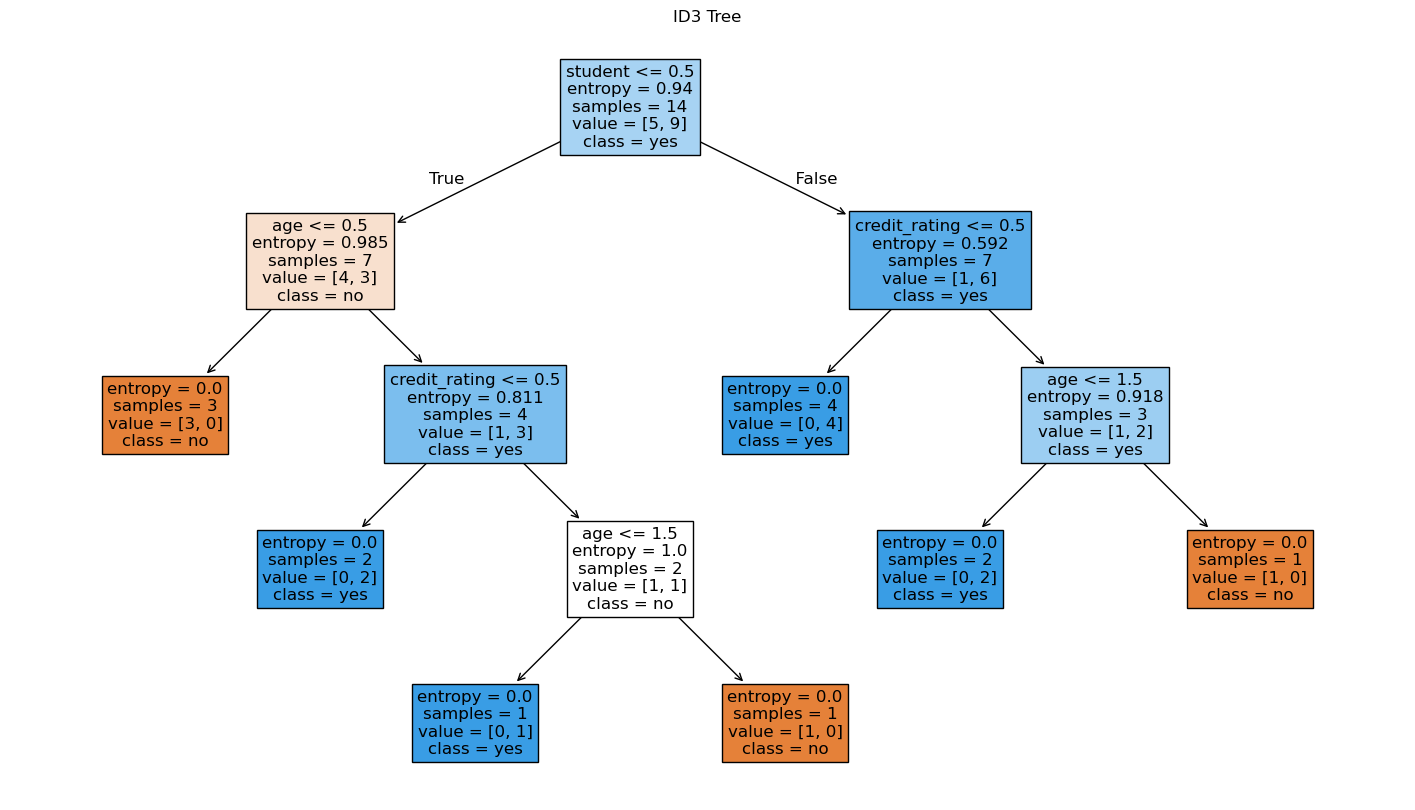

In [5]:
# 시각화
plt.figure(figsize=(18, 10))
plot_tree(id3, 
          feature_names=X.columns, 
          class_names=['no', 'yes'], 
          filled=True, fontsize=12)
plt.title("ID3 Tree")
plt.show()

In [6]:
# 예측할 샘플
#: [age, income, student, credit_rating]
#: [youth, medium, yes, fair]
new_data = [[0, 1, 1, 0]]

# 예측
prediction = id3.predict(new_data)
print("구매 예측 결과:", "yes" if prediction[0] == 1 else "no")

구매 예측 결과: yes


C:\Users\DANA-LAB\.conda\envs\ml\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [7]:
# CART 모델 훈련
cart = DecisionTreeClassifier(criterion="gini", random_state=0)
cart.fit(X, y)

DecisionTreeClassifier(random_state=0)

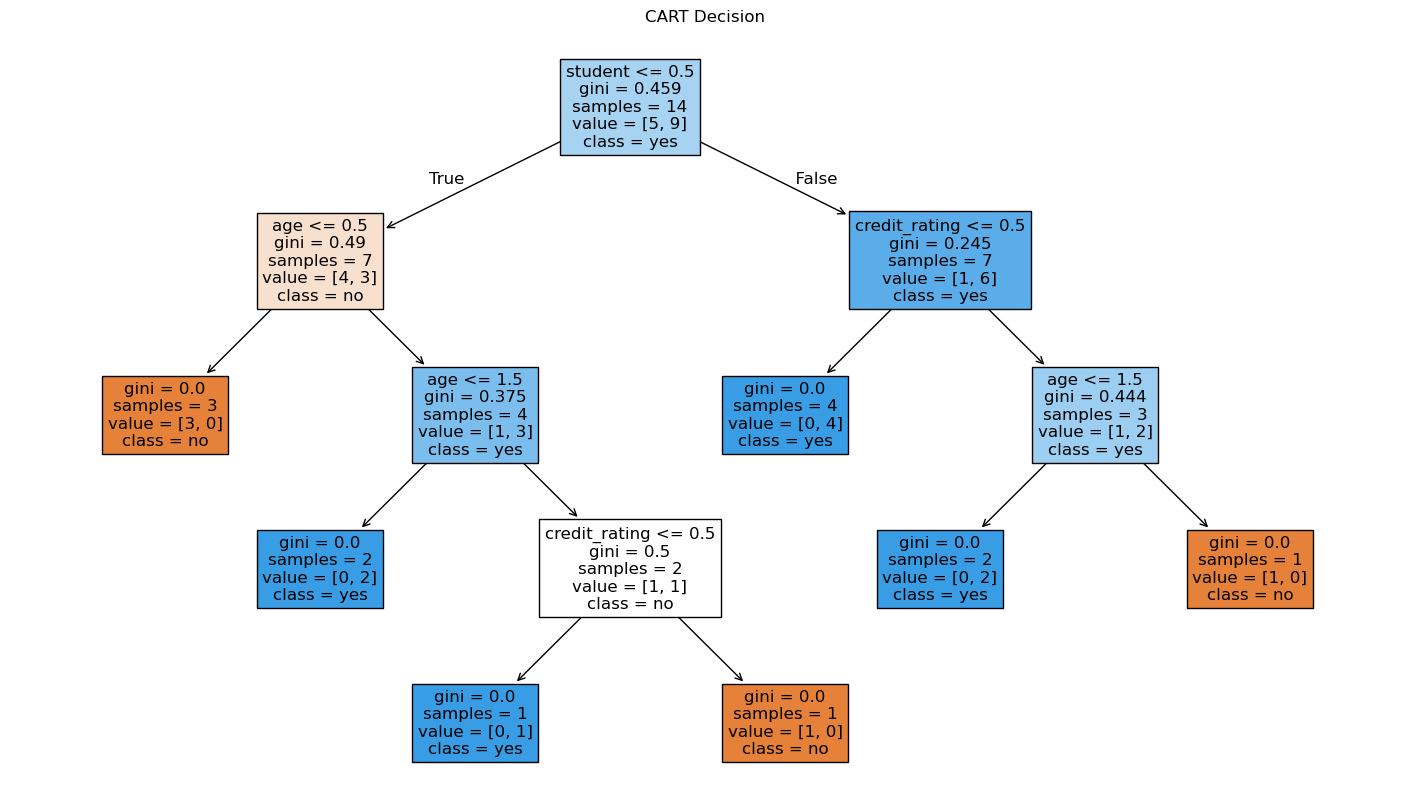

In [8]:
plt.figure(figsize=(18, 10))
plot_tree(
    cart,
    feature_names=X.columns,
    class_names=["no", "yes"],
    filled=True,
    fontsize=12
)
plt.title("CART Decision ")
plt.show()

In [9]:
wine = pd.read_csv("https://raw.githubusercontent.com/prof-dana/Lecture-Code/refs/heads/main/AdvancedMachineLearning/data/wine.csv")
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6497 non-null   float64
 2   volatile acidity      6497 non-null   float64
 3   citric acid           6497 non-null   float64
 4   residual sugar        6497 non-null   float64
 5   chlorides             6497 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6497 non-null   float64
 10  sulphates             6497 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [10]:
#매핑
wine['type'].map({'red': 0, 'white': 1})

#분리
col = ['alcohol', 'residual sugar', 'pH']
data = wine[col]
target = wine['type']

data.describe()

,alcohol,residual sugar,pH
count,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501
std,1.192712,4.757804,0.160787
min,8.000000,0.600000,2.720000
25%,9.500000,1.800000,3.110000
50%,10.300000,3.000000,3.210000
75%,11.300000,8.100000,3.320000
max,14.900000,65.800000,4.010000


In [11]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(
       data, target, test_size=0.2, random_state=42)

print(train_input.shape, test_input.shape)

(5197, 3) (1300, 3)


In [12]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
ss.fit(train_input)
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)

train_scaled[:3]

array([[ 0.01376574,  0.4646116 , -0.16888369],
       [ 1.60871671, -0.70299854,  0.26967864],
       [ 1.10504798, -0.70299854,  1.20945505]])

In [13]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(train_scaled, train_target)

pre_dt = DecisionTreeClassifier(max_depth=3, random_state=42)
pre_dt.fit(train_scaled, train_target)

DecisionTreeClassifier(max_depth=3, random_state=42)

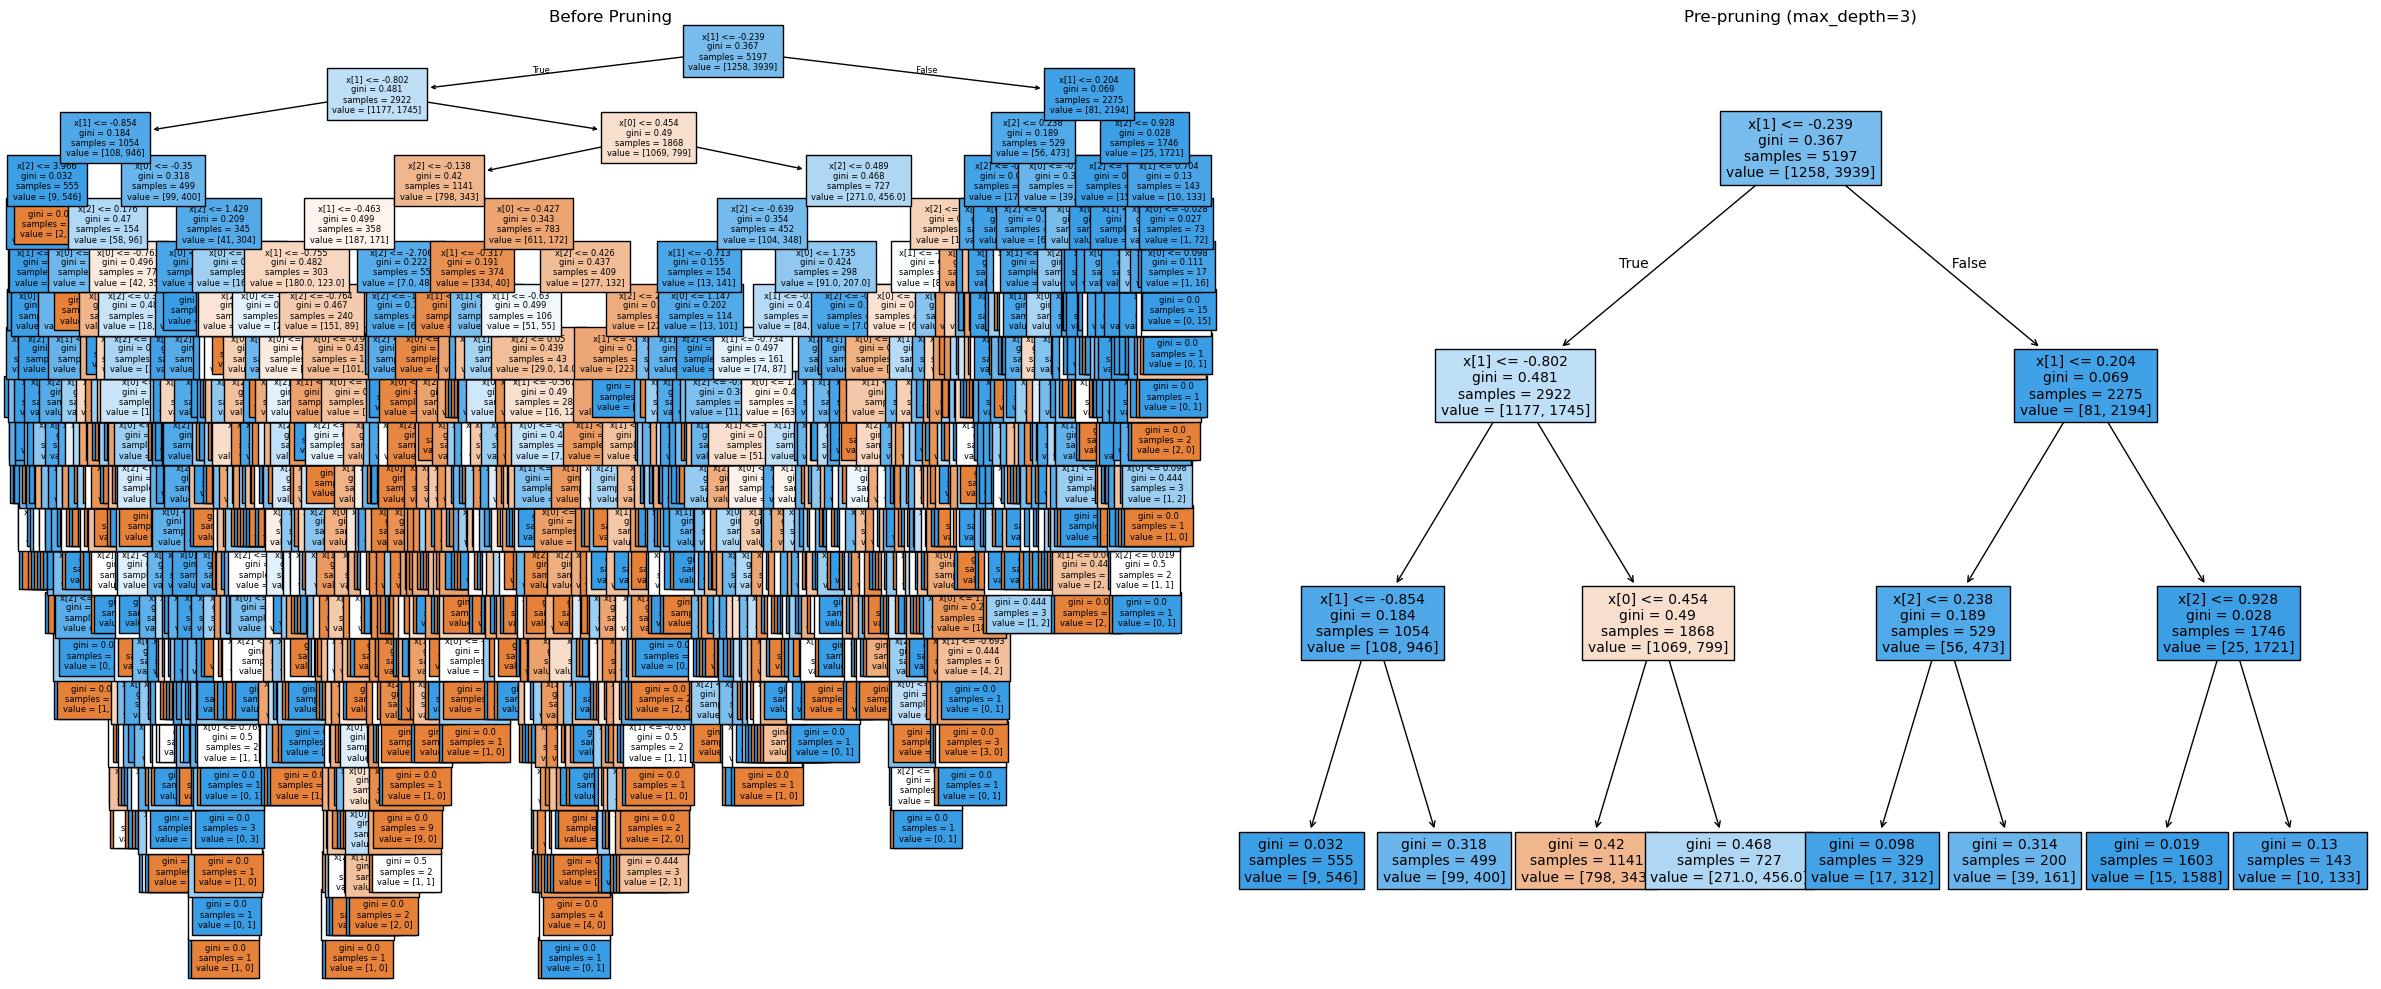

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(24, 10))

plot_tree(dt, filled=True, fontsize=6, ax=axs[0])
axs[0].set_title("Before Pruning")

plot_tree(pre_dt, filled=True, fontsize=10, ax=axs[1])
axs[1].set_title("Pre-pruning (max_depth=3)")

plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import cross_validate
scores = cross_validate(dt, train_input, train_target)
scores

{'fit_time': array([0.00799894, 0.00800014, 0.00900149, 0.00902987, 0.00799298]),
 'score_time': array([0.00300002, 0.00299954, 0.00200152, 0.00199842, 0.00200057]),
 'test_score': array([0.86923077, 0.84615385, 0.87680462, 0.84889317, 0.83541867])}

In [16]:
params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': np.arange(3,10,2), #array([3, 5, 7, 9])
    'min_samples_leaf': np.arange(1,10)
}

In [17]:
from sklearn.model_selection import GridSearchCV

gs = GridSearchCV(
    dt,			        # 탐색할 모델, 난수 시드 고정
    param_grid=params,  # 탐색할 하이퍼파라미터와 후보 값
    scoring='accuracy', # 평가 지표: 정확도
    cv=3,               # 3겹 교차검증 수행
    n_jobs=-1           # 사용 가능한 모든 CPU 코어로 병렬 처리
)

In [18]:
gs.fit(train_input, train_target)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([3, 5, 7, 9]),
                         'min_samples_leaf': array([1, 2, 3, 4, 5, 6, 7, 8, 9])},
             scoring='accuracy')

In [19]:
gs.best_params_

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 9}

In [20]:
post_dt= gs.best_estimator_ # 최적 매개변수로 전체 훈련셋에 재학습된 모델

print(col)
print(post_dt.feature_importances_) #각 열의 중요도

['alcohol', 'residual sugar', 'pH']
[0.16895028 0.68554045 0.14550927]
